# TRACMEX — Minimum-Cost Transportation Problem


## Table of Contents

[1. Problem Description](#scrollTo=ojgBbBnyoASy)

[2. Mathematical Formulation](#scrollTo=EWXSBe67ZM_Y)

[3. Implementation — Explicit Decision Variables](#scrollTo=BDLnqbA0VFwZ&line=1)

[4. Implementation — Indexed Decision Variables](#scrollTo=WROS9vrcm6IY)

[5. Generating Larger Transportation Instances](#scrollTo=eoErRngbzzmB)

[6. Transportation Optimization Using Excel Data](#scrollTo=kxqt009WoiaP)


## [1. Problem description](#scrollTo=VgZ7TtirY4Br)



TRACMEX expects to receive **2,000 diesel engines**, distributed among three Mexican seaports: **Tampico, Veracruz, and Manzanillo**. The supply table below shows the number of engines available at each port.

Once the engines arrive and clear customs, they must be transported to manufacturing plants in **Puebla, Saltillo, Pesquería, and Querétaro**. Each plant has a specified production requirement, as shown in the demand table.

Transportation costs depend on the origin–destination route. The cost matrix below gives the **cost per engine** shipped between each port and plant.

### Objective

Determine a distribution plan that **minimizes total transportation cost** while meeting every plant's demand, without exceeding the engines available at any port. Shipment quantities must be nonnegative.

In this example, **total supply equals total demand (2,000 engines)**, so all available engines will be allocated. This is a *balanced transportation problem*.

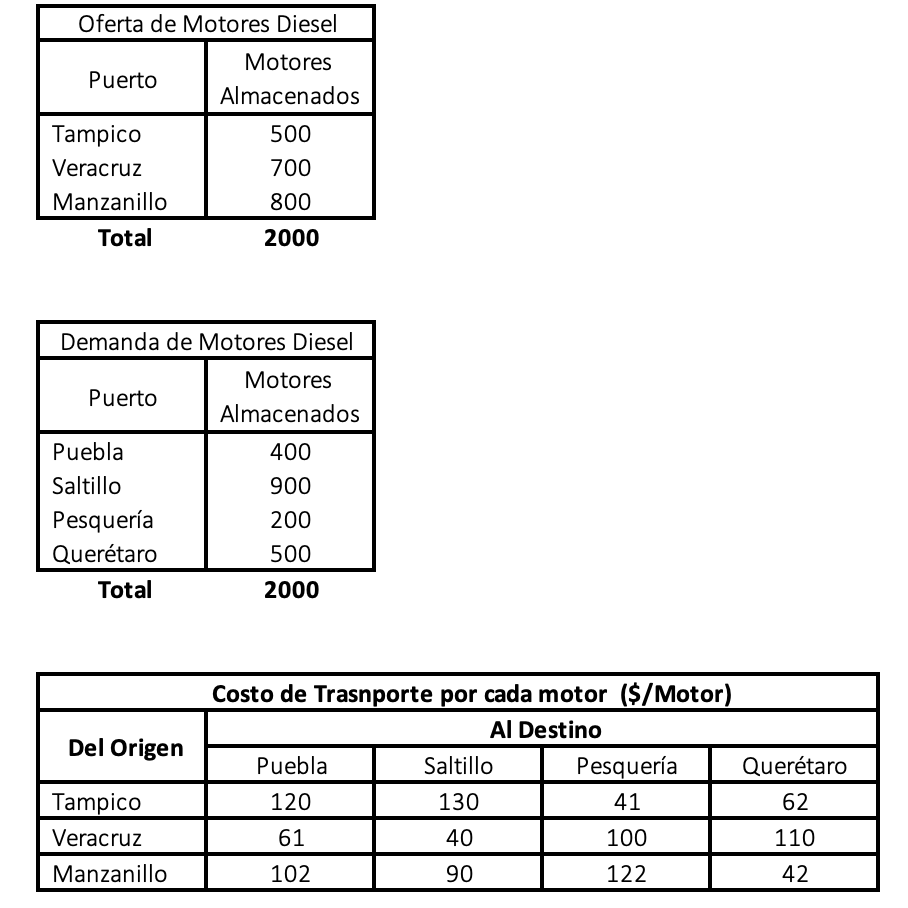

## [2. Mathematical formulation](#scrollTo=VgZ7TtirY4Br)

<details><summary>Decision variables</summary>

Let $x_{ij}$ be the number of engines transported from port $i$ to plant $j$, where

- $i\in\{A,B,C\}$ represents Tampico, Veracruz, and Manzanillo, respectively.
- $j\in\{1,2,3,4\}$ represents Puebla, Saltillo, Pesquería, and Querétaro, respectively.

All $x_{ij}$ must be nonnegative. In the linear programming model, they are treated as continuous variables; since engines are indivisible, the integer interpretation is appropriate for the shipment plan.

<details><summary>Objective function</summary>

Minimize the total transportation cost:

$$
\begin{aligned}
\min\; Z ={}&120x_{A1}+130x_{A2}+41x_{A3}+62x_{A4}\\
&+61x_{B1}+40x_{B2}+100x_{B3}+110x_{B4}\\
&+102x_{C1}+90x_{C2}+122x_{C3}+42x_{C4}.
\end{aligned}
$$

Equivalently,

$$\min Z=\sum_{i\in\{A,B,C\}}\sum_{j=1}^{4} c_{ij}x_{ij},$$

where $c_{ij}$ is the unit transportation cost from port $i$ to plant $j$.

<details><summary>Supply constraints</summary>

For each port, total shipments cannot exceed the available engines:

$$\sum_{j=1}^{4}x_{ij}\le s_i \qquad \text{for each port }i.$$

Here total supply and demand are equal, so these inequalities hold at equality in every feasible solution:

$$
\begin{aligned}
x_{A1}+x_{A2}+x_{A3}+x_{A4}&=500,\\
x_{B1}+x_{B2}+x_{B3}+x_{B4}&=700,\\
x_{C1}+x_{C2}+x_{C3}+x_{C4}&=800.
\end{aligned}
$$

<details><summary>Demand constraints</summary>


Each manufacturing plant must receive exactly the quantity it requires:

$$\sum_{i\in\{A,B,C\}}x_{ij}=d_j\qquad j=1,2,3,4.$$

$$
\begin{aligned}
x_{A1}+x_{B1}+x_{C1}&=400,\\
x_{A2}+x_{B2}+x_{C2}&=900,\\
x_{A3}+x_{B3}+x_{C3}&=200,\\
x_{A4}+x_{B4}+x_{C4}&=500.
\end{aligned}
$$

<details><summary>Nonnegativity</summary>

$$x_{ij}\geq0\qquad \text{for all ports }i\text{ and plants }j.$$

**Balance check:** total supply $=500+700+800=2{,}000$ and total demand $=400+900+200+500=2{,}000$.

## [3. Implementation — explicit decision variables](#scrollTo=VgZ7TtirY4Br)

In [1]:
import pulp as pl
print(pl.__version__)

4.2.0


In [46]:

import pulp as pl

# ----------------------------
# 1) Create the model
# ----------------------------
model = pl.LpProblem("TRACMEX_Transportation", pl.LpMinimize)

# ----------------------------
# 2) Decision variables xij >= 0
# ----------------------------
x11 = model.add_variable("x11", lowBound=0)
x12 = model.add_variable("x12", lowBound=0)
x13 = model.add_variable("x13", lowBound=0)
x14 = model.add_variable("x14", lowBound=0)

x21 = model.add_variable("x21", lowBound=0)
x22 = model.add_variable("x22", lowBound=0)
x23 = model.add_variable("x23", lowBound=0)
x24 = model.add_variable("x24", lowBound=0)

x31 = model.add_variable("x31", lowBound=0)
x32 = model.add_variable("x32", lowBound=0)
x33 = model.add_variable("x33", lowBound=0)
x34 = model.add_variable("x34", lowBound=0)




In [47]:
# Put them in a list (for printing later)
variables = [x11, x12, x13, x14,
             x21, x22, x23, x24,
             x31, x32, x33, x34]

# Verify variables
for var in variables:
    print(var)

x11
x12
x13
x14
x21
x22
x23
x24
x31
x32
x33
x34


In [3]:
# 3) Objective function (min z)

model += (
    120*x11 + 130*x12 +  41*x13 +  62*x14 +
     61*x21 +  40*x22 + 100*x23 + 110*x24 +
    102*x31 +  90*x32 + 122*x33 +  42*x34
)

model.writeLP("TRACMEX_Transportation.txt")


[x11, x12, x13, x14, x21, x22, x23, x24, x31, x32, x33, x34]

In [4]:
# 4) Supply constraints (Oferta)

model += x11 + x12 + x13 + x14 == 500
model += x21 + x22 + x23 + x24 == 700
model += x31 + x32 + x33 + x34 == 800

model.writeLP("TRACMEX_Transportation.txt")



[x11, x12, x13, x14, x21, x22, x23, x24, x31, x32, x33, x34]

In [5]:
# 5) Demand constraints (Demanda)

model += x11 + x21 + x31 == 400
model += x12 + x22 + x32 == 900
model += x13 + x23 + x33 == 200
model += x14 + x24 + x34 == 500

model.writeLP("TRACMEX_Transportation.txt")

[x11, x12, x13, x14, x21, x22, x23, x24, x31, x32, x33, x34]

In [6]:
!apt-get update -qq
!apt-get install -y coinor-cbc

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  coinor-libcbc3.1 coinor-libcgl1 coinor-libclp1 coinor-libcoinutils3v5
  coinor-libosi1v5
The following NEW packages will be installed:
  coinor-cbc coinor-libcbc3.1 coinor-libcgl1 coinor-libclp1
  coinor-libcoinutils3v5 coinor-libosi1v5
0 upgraded, 6 newly installed, 0 to remove and 42 not upgraded.
Need to get 2,911 kB of archives.
After this operation, 7,857 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 coinor-libcoinutils3v5 amd64 2.11.4+repack1-4 [469 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 coinor-libosi1v5 amd64 0.108.9+ds-1 [329 kB]
Get:3 http://archive.ubuntu.com/ub

In [7]:
!which cbc
!cbc -stop

/usr/bin/cbc
Welcome to the CBC MILP Solver 
Version: 2.10.11 
Build Date: Jan 21 2024 

command line - cbc -stop (default strategy 1)
Total time (CPU seconds):       0.00   (Wallclock seconds):       0.00



In [8]:
# 6) Solve

stats = model.solve(pl.COIN_CMD(msg=False))


# 7) Print results

print("Status:", stats.status_str)

if stats.has_solution:
    print("Minimum cost:", pl.value(model.objective))

    print("\nShipments (only positive):")
    for v in variables:
        if v.value() is not None and v.value() > 1e-6:
            print(v.name, "=", v.value())
else:
    print("No solution available.")

# ----------------------------
# 8) Export LP model
# ----------------------------
model.writeLP("TRACMEX_Transportation.lp")


Status: Optimal
Minimum cost: 121400.0

Shipments (only positive):
x11 = 300.0
x13 = 200.0
x22 = 700.0
x31 = 100.0
x32 = 200.0
x34 = 500.0


[x11, x12, x13, x14, x21, x22, x23, x24, x31, x32, x33, x34]

## [4.  Implementation — indexed decision variables](#scrollTo=VgZ7TtirY4Br)

In [9]:
import pulp as pl


origins = ["Tampico", "Veracruz", "Manzanillo"]
destinations = ["Puebla", "Saltillo", "Pesqueria", "Queretaro"]

supply = [500, 700, 800]          # aligned with origins
demand = [400, 900, 200, 500]     # aligned with destinations

# Cost table aligned with origins x destinations
costList = [
    [120, 130,  41,  62],  # Tampico -> (Puebla, Saltillo, Pesqueria, Queretaro)
    [ 61,  40, 100, 110],  # Veracruz -> ...
    [102,  90, 122,  42],  # Manzanillo -> ...
]


In [10]:
nd = len(destinations)
no = len(origins)

In [11]:

# 1) Create the optimization problem
modelB = pl.LpProblem("TRACMEX_Transportation", pl.LpMinimize)

# 2) Define Decision variables x[i][j] >= 0
x = modelB.add_variable_dicts(
    "x",
    (range(no), range(nd)),
    lowBound=0,
    cat="Continuous"
)

# 3) Objective: min sum_ij cost_ij * x_ij
modelB += pl.lpSum(
    costList[i][j] * x[i][j]
    for i in range(no)
    for j in range(nd)
)

modelB.writeLP("test0.txt")


[x_0_0,
 x_0_1,
 x_0_2,
 x_0_3,
 x_1_0,
 x_1_1,
 x_1_2,
 x_1_3,
 x_2_0,
 x_2_1,
 x_2_2,
 x_2_3]

In [12]:
# 4) Supply constraints: sum_j x_ij = supply_i
for i in range(no):
    modelB += pl.lpSum(x[i][j] for j in range(nd)) == supply[i], f"Supply_{i}"

# 5) Demand constraints: sum_i x_ij = demand_j
for j in range(nd):
    modelB += pl.lpSum(x[i][j] for i in range(no)) == demand[j], f"Demand_{j}"

# 6) Export to LP file (human-readable)
modelB.writeLP("TRACMEX_Transportation.lp")

[x_0_0,
 x_0_1,
 x_0_2,
 x_0_3,
 x_1_0,
 x_1_1,
 x_1_2,
 x_1_3,
 x_2_0,
 x_2_1,
 x_2_2,
 x_2_3]

In [13]:

# 7) Solve
stats = modelB.solve(pl.COIN_CMD(path="/usr/bin/cbc", msg=False))

# 8) Print results
print("Status:", stats.status_str)

if stats.has_solution:
    print("Minimum cost:", pl.value(modelB.objective))

    print("\nShipments (only positive):")
    for i in range(no):
        for j in range(nd):
            val = x[i][j].value()
            if val is not None and val > 1e-6:
                print(f"{origins[i]} -> {destinations[j]} : {val}")
else:
    print("No solution available.")


Status: Optimal
Minimum cost: 121400.0

Shipments (only positive):
Tampico -> Puebla : 300.0
Tampico -> Pesqueria : 200.0
Veracruz -> Saltillo : 700.0
Manzanillo -> Puebla : 100.0
Manzanillo -> Saltillo : 200.0
Manzanillo -> Queretaro : 500.0


### 3.1 How the mathematical model maps to PuLP

<details><summary>1) Create the optimization problem</summary>

```python
modelB = pl.LpProblem("TRACMEX_Transportation", pl.LpMinimize)
```

1. You create an LP model named `"TRACMEX_Transportation"`.
2. `pl.LpMinimize` says the objective is **minimization** (min total cost).

Math meaning: $\min Z$

</details>

<details><summary>2) Decision variables $x_{ij} \ge 0$</summary>

```python
x = modelB.add_variable_dicts(
    "x",
    (range(len(origins)), range(len(destinations))),
    lowBound=0,
    cat="Continuous"
)
```

1. This builds variables **indexed by integers**:

   * $i = 0,1,2$ for origins (Tampico, Veracruz, Manzanillo)
   * $j = 0,1,2,3$ for destinations (Puebla, Saltillo, Pesquería, Querétaro)
2. `lowBound=0` makes all shipments nonnegative: (x_{ij} \ge 0).
3. `cat="Continuous"` means **fractional shipments are allowed** (not necessarily integer).

Math meaning: $x_{ij} \ge 0 \quad \forall i,j$

Interpretation: $x[i][j]$ is “how many units shipped from origin $i$ to destination $j$”.

</details>

<details><summary>3) Objective function: minimize total transportation cost</summary>

```python
model += pl.lpSum(costList[i][j] * x[i][j]
                  for i in range(len(origins))
                  for j in range(len(destinations)))
```

1. `lpSum(...)` builds a symbolic sum.
2. It sums over every origin–destination pair.
3. Each term is “cost per unit * shipped amount”.

Math meaning: $ \min Z = \sum_{i}\sum_{j} c_{ij},x_{ij}$
where $c_{ij} = \text{costList}[i][j]$.

</details>

<details><summary>4) Supply constraints - each origin must ship exactly its supply</summary>

```python
for i in range(len(origins)):
    model += pl.lpSum(x[i][j] for j in range(len(destinations))) == supply[i], f"Supply_{origins[i]}"
```

For each origin $i$:

1. Sum shipments from that origin to all destinations:
   $\sum_j x_{ij}$.
2. Force it to equal the available supply at that origin.

Math meaning: $\sum_{j} x_{ij} = s_i \quad \forall i$

Interpretation: Tampico ships *exactly 500*, Veracruz *exactly 700*, Manzanillo *exactly 800*.

*(Note: using `==` means you assume all supply must be shipped; that’s standard when total supply = total demand.)*

</details>

<details><summary>5) Demand constraints -  each destination must receive exactly its demand</summary>

```python
for j in range(len(destinations)):
    model += pl.lpSum(x[i][j] for i in range(len(origins))) == demand[j], f"Demand_{destinations[j]}"
```

For each destination (j):

1. Sum shipments coming into that destination from all origins:
   $\sum_i x_{ij}$
2. Force it to equal the demand needed there.

Math meaning: $\sum_{i} x_{ij} = d_j \quad \forall j$

Interpretation: Puebla receives *400*, Saltillo *900*, Pesquería *200*, Querétaro *500*.

</details>

<details><summary>6) Export the model to an LP text file </summary>

```python
model.writeLP("TRACMEX_Transportation.lp")
```

This writes a human-readable file containing:

1. The objective expression
2. All constraints
3. Variable bounds

useful for debugging.

</details>

<details><summary>7) Solve the model</summary>

```python
model.solve(pl.PULP_CBC_CMD(msg=False))
```

1. Uses the default open-source solver **CBC**.
2. `msg=False` hides solver logs.

Interpretation: the solver finds values of all $x_{ij}$ minimizing cost while satisfying supply/demand constraints.

</details>

<details><summary>8) Print status and objective value </summary>

```python
print("Status:", pl.LpStatus[model.status])
print("Minimum cost:", pl.value(model.objective))
```

1. `model.status` is a code; `LpStatus[...]` converts it to a readable string like:

   * “Optimal”
   * “Infeasible”
   * “Unbounded”
2. `pl.value(model.objective)` evaluates the objective at the solution.

Interpretation: tells you whether you got an optimal plan and what its total transportation cost is.

</details>

<details><summary>9) Print only the positive shipments</summary>

```python
for i in range(len(origins)):
    for j in range(len(destinations)):
        val = x[i][j].value()
        if val and val > 1e-6:
            print(f"{origins[i]} -> {destinations[j]} : {val}")
```

1. Loops over all $x_{ij}$.
2. Reads the solution value with `.value()`.
3. Prints only those that are nonzero (tolerance `1e-6` avoids printing tiny numerical noise).

Interpretation: you get the actual shipping plan, e.g.

* Tampico → Pesquería: 200
* Veracruz → Saltillo: 700
* etc. (whatever the optimal solution is)

</details>

<details><summary>Bottom points</summary>

1. **Balanced transportation condition**: your equalities work nicely because
   total supply = 500+700+800 = **2000**
   total demand = 400+900+200+500 = **2000**
2. If totals were not equal, you’d need either:

   * a dummy origin/destination, or
   * replace `==` by `<=` / `>=` depending on the meaning, but this is not a transportation problem.
</details>

### Inspecting the model

The indexed model above uses numeric indices: `x[i][j]`, where `i` and `j` correspond to positions in `origins` and `destinations`.

```python
print("Decision variables:")
for i in range(no):
    for j in range(nd):
        print(f"{origins[i]} -> {destinations[j]}: {x[i][j].name}")

print("\nObjective:")
print(modelB.objective)

print("\nConstraints:")
for name, constraint in modelB.constraints.items():
    print(name, ":", constraint)
```

Use `modelB` here rather than `model`, since Section 3 creates a separate model from Section 2.

## [5. Generating larger transportation instances](#scrollTo=VgZ7TtirY4Br)

In [14]:
import random
import time

def create_transport_instance(num_origins,
                              num_destinations,
                              supply_min=200,
                              supply_max=800,
                              cost_min=10,
                              cost_max=150,
                              seed=None):

    if seed is not None:
        random.seed(seed)

    origins = [f"Origin{i+1}" for i in range(num_origins)]
    destinations = [f"Dest{j+1}" for j in range(num_destinations)]

    supply = [random.randint(supply_min, supply_max) for _ in range(num_origins)]
    total_supply = sum(supply)

    demand = []
    remaining = total_supply

    for j in range(num_destinations - 1):
        d = random.randint(1, remaining)   # demand at least 1
        demand.append(d)
        remaining -= d

        if remaining == 0:
            break

    # fill remaining destinations with 0 if needed
    while len(demand) < num_destinations - 1:
        demand.append(0)

    demand.append(remaining)

    costList = []
    for i in range(num_origins):
        row = [random.randint(cost_min, cost_max) for _ in range(num_destinations)]
        costList.append(row)

    return origins, destinations, supply, demand, costList


# ----------------------------
# Generate random instance
# ----------------------------
seed = int(time.time())

origins, destinations, supply, demand, costList = create_transport_instance(
    num_origins=1300,
    num_destinations=800,
    seed=seed
)

# ----------------------------
# Write instance into a file
# ----------------------------
filename = "transport_instance.py"

with open(filename, "w") as f:
    f.write("# Transportation Problem Instance\n")
    f.write(f"# Random seed used: {seed}\n\n")

    f.write(f"origins = {origins}\n\n")
    f.write(f"destinations = {destinations}\n\n")
    f.write(f"supply = {supply}\n\n")
    f.write(f"demand = {demand}\n\n")
    f.write("costList = [\n")
    for row in costList:
        f.write(f"    {row},\n")
    f.write("]\n")

print("Instance written to:", filename)
print("Total Supply =", sum(supply))
print("Total Demand =", sum(demand))


Instance written to: transport_instance.py
Total Supply = 654002
Total Demand = 654002


In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
EXCEL_PATH = "/content/drive/MyDrive/Colab Notebooks/clases/IN2009B/m3_2009jobish.xlsx"
SHEET      = "M314"

df = pd.read_excel(EXCEL_PATH, sheet_name=SHEET, header=1).dropna(how="all")
df.head()

,Unnamed: 0,Unnamed: 1,Dest1,Dest2,Dest3,Dest4,Dest5,Dest6,Dest7,Dest8,Dest9,Dest10,Supply
0,NaN,Origin1,112.0,189.0,102.0,24.0,116.0,81.0,198.0,30.0,112.0,131.0,537.0
1,NaN,Origin2,84.0,97.0,126.0,109.0,113.0,161.0,140.0,159.0,62.0,11.0,905.0
2,NaN,Origin3,97.0,167.0,47.0,139.0,197.0,30.0,170.0,67.0,31.0,98.0,362.0
3,NaN,Origin4,58.0,68.0,179.0,197.0,24.0,199.0,199.0,184.0,199.0,60.0,919.0
4,NaN,Origin5,117.0,64.0,73.0,140.0,60.0,144.0,30.0,82.0,176.0,27.0,880.0


In [32]:
origins = df.iloc[:, 1].dropna().tolist()
origins = origins[:-1]   # drop the last one ("Demand")
#origins

In [33]:
# Use the number of populated demand cells to determine the destination count.
# This avoids including a stray blank/summary column in the Excel header.
demand_cells = df.iloc[-2, 2:-1].dropna()
destinations = df.columns[2:2 + len(demand_cells)].tolist()
print("Destinations:", destinations)

Destinations: ['Dest1', 'Dest2', 'Dest3', 'Dest4', 'Dest5', 'Dest6', 'Dest7', 'Dest8', 'Dest9', 'Dest10']


In [34]:
supply = df.iloc[:-1, -1].dropna()
supply = supply.astype(int).tolist()
sum(supply)

18422

In [35]:
demand = df.iloc[-2, 2:-1].dropna()
demand = demand.astype(int).tolist()
sum(demand)

18422

In [36]:
# Extract one cost for each origin and destination.
costList = df.iloc[:len(origins), 2:2 + len(destinations)].astype(int).values.tolist()
assert len(costList) == len(origins)
assert all(len(row) == len(destinations) for row in costList)
costList

[[112, 189, 102, 24, 116, 81, 198, 30, 112, 131],
 [84, 97, 126, 109, 113, 161, 140, 159, 62, 11],
 [97, 167, 47, 139, 197, 30, 170, 67, 31, 98],
 [58, 68, 179, 197, 24, 199, 199, 184, 199, 60],
 [117, 64, 73, 140, 60, 144, 30, 82, 176, 27],
 [141, 98, 69, 23, 18, 99, 62, 139, 93, 101],
 [120, 197, 181, 17, 184, 44, 90, 173, 59, 113],
 [141, 11, 143, 63, 115, 13, 63, 155, 53, 171],
 [199, 23, 104, 57, 24, 199, 49, 91, 120, 62],
 [33, 163, 197, 133, 50, 166, 24, 54, 74, 98],
 [80, 18, 97, 138, 145, 72, 148, 90, 145, 172],
 [172, 42, 132, 14, 50, 37, 144, 81, 21, 171],
 [42, 57, 160, 71, 46, 108, 181, 113, 44, 110],
 [184, 140, 10, 14, 151, 112, 36, 146, 24, 99],
 [51, 133, 188, 72, 105, 61, 105, 141, 160, 152],
 [180, 38, 45, 22, 169, 80, 196, 95, 37, 75],
 [179, 54, 71, 194, 143, 37, 37, 117, 53, 93],
 [39, 199, 84, 137, 101, 199, 138, 130, 36, 199],
 [130, 125, 12, 112, 164, 146, 71, 174, 60, 181],
 [161, 68, 127, 169, 105, 189, 122, 71, 195, 61],
 [21, 48, 139, 140, 122, 110, 122, 19

In [37]:
import numpy as np

total_cost_sum = np.sum(costList)
print(total_cost_sum)


32944


## [6. Solving a transportation instance imported from Excel](#scrollTo=VgZ7TtirY4Br)



The Excel sheet is an **external input**. Confirm that the destination labels, cost columns, supply values, and demand values refer to the same data before solving.

In [38]:
no = len(origins)
nd = len(destinations)
no

30

In [39]:

print("Origins:", origins)
print("Destinations:", destinations)

print("Number of origins (no):", no)
print("Number of destinations (nd):", nd)

print("Cost matrix:")
for i, row in enumerate(costList):
    print(f"Row {i}: {row} | Columns: {len(row)}")

print("Expected matrix:", no, "rows x", nd, "columns")
print("Actual rows:", len(costList))

print("Supply:", supply)
print("Demand:", demand)


Origins: ['Origin1', 'Origin2', 'Origin3', 'Origin4', 'Origin5', 'Origin6', 'Origin7', 'Origin8', 'Origin9', 'Origin10', 'Origin11', 'Origin12', 'Origin13', 'Origin14', 'Origin15', 'Origin16', 'Origin17', 'Origin18', 'Origin19', 'Origin20', 'Origin21', 'Origin22', 'Origin23', 'Origin24', 'Origin25', 'Origin26', 'Origin27', 'Origin28', 'Origin29', 'Origin30']
Destinations: ['Dest1', 'Dest2', 'Dest3', 'Dest4', 'Dest5', 'Dest6', 'Dest7', 'Dest8', 'Dest9', 'Dest10']
Number of origins (no): 30
Number of destinations (nd): 10
Cost matrix:
Row 0: [112, 189, 102, 24, 116, 81, 198, 30, 112, 131] | Columns: 10
Row 1: [84, 97, 126, 109, 113, 161, 140, 159, 62, 11] | Columns: 10
Row 2: [97, 167, 47, 139, 197, 30, 170, 67, 31, 98] | Columns: 10
Row 3: [58, 68, 179, 197, 24, 199, 199, 184, 199, 60] | Columns: 10
Row 4: [117, 64, 73, 140, 60, 144, 30, 82, 176, 27] | Columns: 10
Row 5: [141, 98, 69, 23, 18, 99, 62, 139, 93, 101] | Columns: 10
Row 6: [120, 197, 181, 17, 184, 44, 90, 173, 59, 113] | Col

In [40]:

assert no == len(origins), "Origins count mismatch"
assert nd == len(destinations), "Destinations count mismatch"

assert len(costList) == no, "Incorrect number of cost rows"

assert all(len(row) == nd for row in costList), \
    "Incorrect number of cost columns"

assert len(supply) == no, "Supply count mismatch"
assert len(demand) == nd, "Demand count mismatch"

print("All dimensions are correct!")


All dimensions are correct!


In [41]:
import pulp as pl

# Validate imported data before building the model.
no, nd = len(origins), len(destinations)
assert len(supply) == no, "Supply count does not match origins"
assert len(demand) == nd, "Demand count does not match destinations"
assert len(costList) == no and all(len(row) == nd for row in costList), "Cost matrix dimension mismatch"
assert sum(supply) == sum(demand), "This equality-constrained model requires balanced supply and demand"

model = pl.LpProblem("TRACMEX_Transportation", pl.LpMinimize)
x = model.add_variable_dicts("x", (range(no), range(nd)), lowBound=0, cat="Continuous")

model += pl.lpSum(costList[i][j] * x[i][j] for i in range(no) for j in range(nd))
for i in range(no):
    model += pl.lpSum(x[i][j] for j in range(nd)) == supply[i], f"Supply_{i}"
for j in range(nd):
    model += pl.lpSum(x[i][j] for i in range(no)) == demand[j], f"Demand_{j}"

model.writeLP("TRACMEX_Transportation.lp")


stats = model.solve(pl.COIN_CMD(path="/usr/bin/cbc", msg=False))
print("Status:", stats.status_str)
if stats.has_solution:
    print("Minimum cost:", pl.value(model.objective))
    print("\nPositive shipments:")
    for i in range(no):
        for j in range(nd):
            val = x[i][j].value()
            if val is not None and val > 1e-6:
                print(f"{origins[i]} -> {destinations[j]}: {val:g}")
else:
    print("No solution available.")

Status: Optimal
Minimum cost: 647850.0

Positive shipments:
Origin1 -> Dest8: 537
Origin2 -> Dest9: 746
Origin2 -> Dest10: 159
Origin3 -> Dest3: 362
Origin4 -> Dest5: 919
Origin5 -> Dest7: 880
Origin6 -> Dest5: 360
Origin7 -> Dest4: 779
Origin8 -> Dest6: 597
Origin9 -> Dest5: 476
Origin10 -> Dest5: 225
Origin10 -> Dest7: 478
Origin11 -> Dest2: 591
Origin12 -> Dest4: 334
Origin13 -> Dest5: 394
Origin14 -> Dest3: 600
Origin15 -> Dest1: 743
Origin15 -> Dest6: 96
Origin16 -> Dest3: 162
Origin16 -> Dest4: 70
Origin17 -> Dest3: 467
Origin17 -> Dest6: 142
Origin17 -> Dest9: 278
Origin18 -> Dest9: 659
Origin19 -> Dest3: 669
Origin20 -> Dest8: 574
Origin21 -> Dest1: 221
Origin22 -> Dest2: 679
Origin22 -> Dest4: 270
Origin23 -> Dest9: 869
Origin24 -> Dest9: 237
Origin25 -> Dest1: 429
Origin26 -> Dest8: 564
Origin27 -> Dest5: 762
Origin28 -> Dest1: 183
Origin28 -> Dest7: 454
Origin29 -> Dest4: 975
Origin30 -> Dest3: 81
Origin30 -> Dest8: 401


In [43]:

from openpyxl.worksheet.table import Table, TableStyleInfo
from openpyxl.utils import get_column_letter

# Name of the solution worksheet
sheet_name = f"{SHEET}_solution"


# Create a DataFrame from the optimized shipments
tableX = pd.DataFrame(
    [
        [x[i][j].value() for j in range(nd)]
        for i in range(no)
    ],
    index=origins,
    columns=destinations
)

tableX.index.name = "Origin"

# Display solution
display(tableX)

# Save solution to existing Excel workbook
with pd.ExcelWriter(
    EXCEL_PATH,
    engine="openpyxl",
    mode="a",
    if_sheet_exists="replace"
) as writer:

    # Convert index into a regular column
    df = tableX.reset_index()
    df.columns = df.columns.map(str)

    # Write solution
    df.to_excel(
        writer,
        sheet_name=sheet_name,
        index=False
    )

    ws = writer.sheets[sheet_name]

    # Define Excel Table range
    last_col = get_column_letter(df.shape[1])
    last_row = len(df) + 1

    tab = Table(
        displayName="TRACMEX_Solution",
        ref=f"A1:{last_col}{last_row}"
    )

    # Apply table formatting
    style = TableStyleInfo(
        name="TableStyleMedium2",
        showFirstColumn=False,
        showLastColumn=False,
        showRowStripes=True,
        showColumnStripes=False
    )

    tab.tableStyleInfo = style
    ws.add_table(tab)

    # Freeze header and origin column
    ws.freeze_panes = "B2"

    # Adjust column widths
    for column in ws.columns:
        letter = column[0].column_letter
        ws.column_dimensions[letter].width = 18

print("Solution saved successfully!")


,Dest1,Dest2,Dest3,Dest4,Dest5,Dest6,Dest7,Dest8,Dest9,Dest10
Origin,,,,,,,,,,
Origin1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,537.0,0.0,0.0
Origin2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,746.0,159.0
Origin3,0.0,0.0,362.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Origin4,0.0,0.0,0.0,0.0,919.0,0.0,0.0,0.0,0.0,0.0
Origin5,0.0,0.0,0.0,0.0,0.0,0.0,880.0,0.0,0.0,0.0
Origin6,0.0,0.0,0.0,0.0,360.0,0.0,0.0,0.0,0.0,0.0
Origin7,0.0,0.0,0.0,779.0,0.0,0.0,0.0,0.0,0.0,0.0
Origin8,0.0,0.0,0.0,0.0,0.0,597.0,0.0,0.0,0.0,0.0
Origin9,0.0,0.0,0.0,0.0,476.0,0.0,0.0,0.0,0.0,0.0


Solution saved successfully!


In [29]:
print('___')

___
